<a href="https://colab.research.google.com/github/mlbyhoang/marketing-attribution/blob/main/notebooks/02_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 – Exploratory Data Analysis

This notebook explores the customer journeys, engineers touchpoint- and journey-level features, removes journey-length outliers, and prepares the final dataset for conversion modelling.

In [1]:
# Load libraries
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Connect to Google Drive
from google.colab import drive, userdata
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Load processed data path from user data / secrets
PROCESSED_DATA_PATH = userdata.get("MTA_PROCESSED_PATH")

In [4]:
# Load processed dataset and inspect structure
df_journeys = pd.read_parquet(PROCESSED_DATA_PATH)

print("Shape:", df_journeys.shape)
print("Columns:", df_journeys.columns.tolist())

Shape: (46701, 5)
Columns: ['ga_cid', 'sequence', 'seq_times', 'touchpoint_sum', 'order']


In [5]:
# Display first few rows
df_journeys.head()

,ga_cid,sequence,seq_times,touchpoint_sum,order
0,GA1.1.1000041479.1771496747,[sh_affiliate],"[{'interaction_hour_cos': -0.9659258262890682,...",1,0
1,GA1.1.1000106037.1771597619,[paid_search],"[{'interaction_hour_cos': -0.7071067811865479,...",1,0
2,GA1.1.100021107.1771445497,"[sh_display, sh_display, sh_display, sh_displa...","[{'interaction_hour_cos': 0.7071067811865474, ...",5,0
3,GA1.1.1000251718.1699952567,[paid_search],"[{'interaction_hour_cos': -1.0, 'interaction_h...",1,0
4,GA1.1.1000258229.1762505696,[Sparhandy_DE_Alwayson_Google_DemandGen],[{'interaction_hour_cos': -0.25881904510252063...,1,0


In [6]:
# Display DataFrame summary and data types
df_journeys.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46701 entries, 0 to 46700
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ga_cid          46701 non-null  object
 1   sequence        46701 non-null  object
 2   seq_times       46701 non-null  object
 3   touchpoint_sum  46701 non-null  int64 
 4   order           46701 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 1.8+ MB


In [7]:
# Display summary statistics
df_journeys.describe()

,touchpoint_sum,order
count,46701.000000,46701.000000
mean,1.842830,0.071348
std,2.268537,0.257407
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,0.000000
max,150.000000,1.000000


In [8]:
# Unnest sequences and get channel counts
channels = df_journeys['sequence'].explode()

channels.value_counts()

,count
sequence,
paid_search,41812
sh_display,11819
sh_affiliate,10024
dh_affiliate,8187
Sparhandy_DE_Alwayson_Google_DemandGen,3625
sh_organic_facebook,2482
high_display,1479
dh_display,1462
simyo_display,1405


In [9]:
# Calculate channel distribution in percentage
channel_distribution = (
    channels
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

channel_distribution

,proportion
sequence,
paid_search,48.58
sh_display,13.73
sh_affiliate,11.65
dh_affiliate,9.51
Sparhandy_DE_Alwayson_Google_DemandGen,4.21
sh_organic_facebook,2.88
high_display,1.72
dh_display,1.70
simyo_display,1.63


In [10]:
# Calculate first and last touch percentages
print("First Touch:")
print(
    df_journeys["sequence"]
    .str[0]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nLast Touch:")
print(
    df_journeys["sequence"]
    .str[-1]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

First Touch:
sequence
paid_search                               52.96
sh_affiliate                              15.00
sh_display                                 8.42
dh_affiliate                               7.35
Sparhandy_DE_Alwayson_Google_DemandGen     4.10
sh_organic_facebook                        3.84
simyo_display                              1.22
sparsim_display                            1.14
dh_display                                 1.11
high_display                               1.05
dh_paid_facebook                           0.95
sh_paid_facebook                           0.82
dh_e_mail                                  0.77
simyo_affiliate                            0.57
sh_e_mail                                  0.38
high_paid_facebook                         0.23
dh_organic_facebook                        0.09
Name: proportion, dtype: float64

Last Touch:
sequence
paid_search                               52.95
sh_affiliate                              15.07
sh_display 

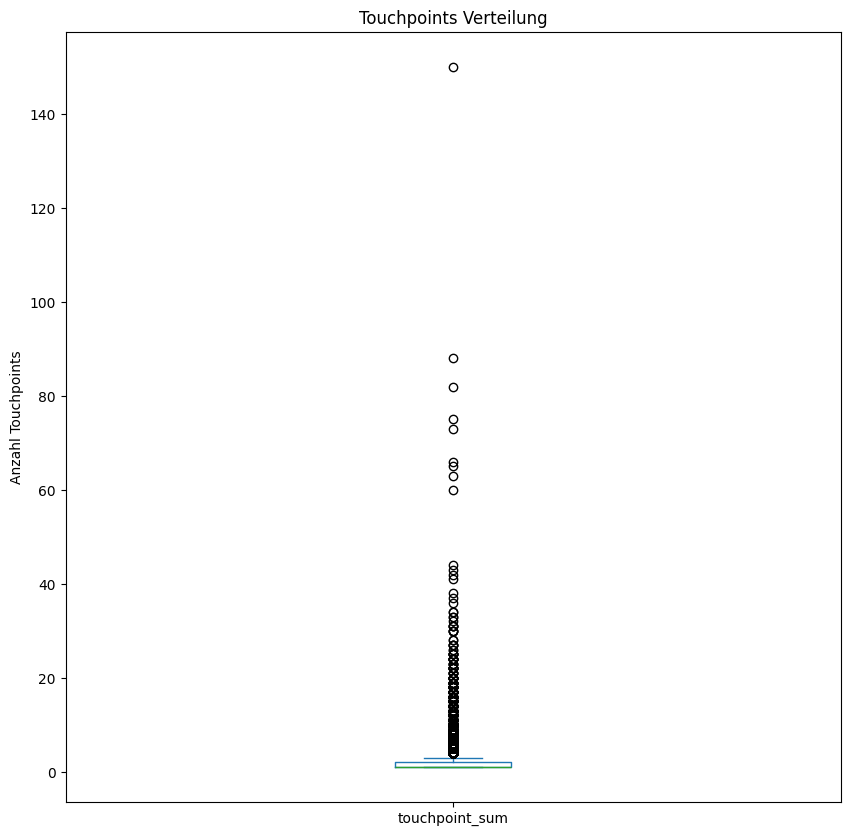

In [11]:
# Distribution of total touchpoints
df_journeys["touchpoint_sum"].plot(
    kind="box",
    title="Touchpoints Verteilung",
    figsize=(10, 10)
)
plt.ylabel("Anzahl Touchpoints")
plt.show()

In [12]:
# Check for outliers
print(df_journeys['touchpoint_sum'].quantile([0.97, 0.98, 0.99, 1.0]))
print(f"\nMax: {df_journeys['touchpoint_sum'].max()}")
print(f"Sequenzen > 10:  {(df_journeys['touchpoint_sum'] > 10).sum()}")
print(f"Sequenzen > 20:  {(df_journeys['touchpoint_sum'] > 20).sum()}")
print(f"Sequenzen > 50:  {(df_journeys['touchpoint_sum'] > 50).sum()}")

0.97      6.0
0.98      7.0
0.99     10.0
1.00    150.0
Name: touchpoint_sum, dtype: float64

Max: 150
Sequenzen > 10:  381
Sequenzen > 20:  68
Sequenzen > 50:  9


In [13]:
# Remove outliers
df_filtered = df_journeys[
    df_journeys["touchpoint_sum"] <= 10
].copy()

print(f"Vorher:  {len(df_journeys)} Sequenzen")
print(f"Nachher: {len(df_filtered)} Sequenzen")
print(
    f"Entfernt: {len(df_journeys) - len(df_filtered)} Sequenzen "
    f"({1 - len(df_filtered) / len(df_journeys):.2%})"
)

print(f"\nConversion Rate vorher:  {df_journeys['order'].mean():.2%}")
print(f"Conversion Rate nachher: {df_filtered['order'].mean():.2%}")
print(f"\nMax Sequenzlänge: {df_filtered['touchpoint_sum'].max()}")

Vorher:  46701 Sequenzen
Nachher: 46320 Sequenzen
Entfernt: 381 Sequenzen (0.82%)

Conversion Rate vorher:  7.13%
Conversion Rate nachher: 7.17%

Max Sequenzlänge: 10


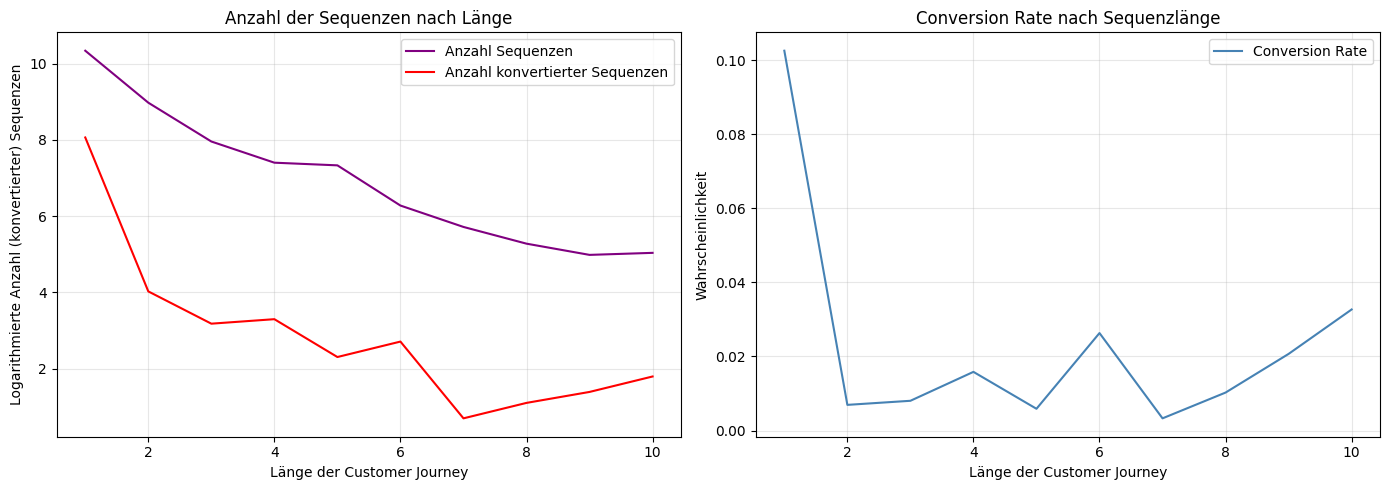

In [14]:
# Prepare data
seq_lengths = df_filtered['touchpoint_sum'].values
converted   = df_filtered['order'].values

max_length = seq_lengths.max()
lengths = np.arange(1, max_length + 1)

# Count of total and converted sequences by length
n_sequences = np.array([(seq_lengths == l).sum() for l in lengths])
n_converted = np.array([((seq_lengths == l) & (converted == 1)).sum() for l in lengths])

# # Conversion rate by length (non-empty sequences only)
with np.errstate(divide='ignore', invalid='ignore'):
    conversion_rate = np.where(n_sequences > 0, n_converted / n_sequences, np.nan)

# Chart 1: Number of sequences by length (log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.plot(lengths, np.log1p(n_sequences), color='purple', label='Anzahl Sequenzen')
ax1.plot(lengths, np.log1p(n_converted), color='red', label='Anzahl konvertierter Sequenzen')
ax1.set_xlabel('Länge der Customer Journey')
ax1.set_ylabel('Logarithmierte Anzahl (konvertierter) Sequenzen')
ax1.set_title('Anzahl der Sequenzen nach Länge')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Chart 2: Conversion rate by sequence length
ax2 = axes[1]
ax2.plot(lengths, conversion_rate, color='steelblue', label='Conversion Rate')
ax2.set_xlabel('Länge der Customer Journey')
ax2.set_ylabel('Wahrscheinlichkeit')
ax2.set_title('Conversion Rate nach Sequenzlänge')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Journey length summary statistics by order
journey_length_comparison = (
    df_filtered
    .groupby("order")["touchpoint_sum"]
    .agg(["count", "mean", "median", "std"])
)

journey_length_comparison

,count,mean,median,std
order,,,,
0,43001,1.760517,1.0,1.427193
1,3319,1.112685,1.0,0.686531


In [16]:
# Calculate click rate per journey and compare by order status
click_rate = df_filtered["seq_times"].apply(
    lambda times: np.mean([tp["is_click"] for tp in times])
)

click_rate.groupby(df_filtered["order"]).agg(
    ["mean", "median", "std"]
)

,mean,median,std
order,,,
0,0.918512,1.0,0.268915
1,0.803523,1.0,0.395692


In [17]:
# Top 20 sequence counts and shares (%)
sequence_counts = df_filtered["sequence"].apply(tuple).value_counts()

sequence_summary = pd.DataFrame({
    "count": sequence_counts,
    "share_pct": (sequence_counts / len(df_filtered) * 100).round(2)
})

sequence_summary.head(20)

,count,share_pct
sequence,,
"(paid_search,)",16501,35.62
"(sh_affiliate,)",5614,12.12
"(paid_search, paid_search)",4377,9.45
"(dh_affiliate,)",2131,4.60
"(sh_display,)",1725,3.72
"(paid_search, paid_search, paid_search)",1474,3.18
"(sh_organic_facebook,)",1366,2.95
"(Sparhandy_DE_Alwayson_Google_DemandGen,)",1158,2.50
"(sh_affiliate, sh_affiliate)",801,1.73


In [18]:
# Save filtered journey dataset
FILTERED_DATA_PATH = userdata.get("MTA_FILTERED_PATH")

df_filtered.to_parquet(
    FILTERED_DATA_PATH,
    index=False
)

print("Filtered dataset saved successfully.")

Filtered dataset saved successfully.
